# LAHAJA: Unit 5 - CART and two ensemble models
Task: predict `native_language` from speech (speaker-independent split).

* Part A: CART (single decision tree, with pruning)
* Part B: Random forest (bagging-type ensemble)
* Part C: AdaBoost (boosting ensemble)

Run all. Set `MAX_CLIPS_PER_FILE = 200` for a quick test, `None` for all clips.

In [ ]:
!pip -q install librosa hmmlearn pygam soundfile

In [ ]:
# ---------------- CONFIG ----------------
MAX_CLIPS_PER_FILE = 200   # 200 = quick test, None = use every clip
SEED = 42
SR = 16000          # sample rate used for features
MAX_SEC = 12        # only the first 12 s of each clip are used
MIN_CLIPS_PER_LANG = 8
TEST_SIZE = 0.25
REQUIRED = [f"test-0000{i}-of-00004.parquet" for i in range(4)]

In [ ]:
import os, io, glob, re, pickle, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
warnings.filterwarnings("ignore")
np.random.seed(SEED)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False

TEST_DIR = r""
search_dirs = [TEST_DIR] if TEST_DIR else ['/content/drive/MyDrive/LAHAJA', '/content/drive/MyDrive', '/content', '.']
files = []
for d in search_dirs:
    files = [p for p in sorted(glob.glob(os.path.join(d, '**', 'test-0000*-of-00004.parquet'), recursive=True))]
    if files: break
if not files and IN_COLAB:
    from google.colab import files as cf
    print("Parquet files not found. Please upload the 4 files.")
    cf.upload()
    files = sorted(glob.glob('/content/test-0000*-of-00004.parquet'))
assert files, "No parquet files found. Put them in MyDrive/LAHAJA/"
missing = [r for r in REQUIRED if r not in [os.path.basename(f) for f in files]]
print("Found:", [os.path.basename(f) for f in files])
if missing: print("WARNING missing:", missing)

Mounted at /content/drive
Found: ['test-00000-of-00004.parquet', 'test-00001-of-00004.parquet', 'test-00002-of-00004.parquet', 'test-00003-of-00004.parquet']


In [ ]:
import soundfile as sf, librosa

HOP, NFFT = 320, 512   # 20 ms hop, 32 ms window at 16 kHz

def decode(raw):
    try:
        y, sr = sf.read(io.BytesIO(raw), dtype='float32')
    except Exception:
        y, sr = librosa.load(io.BytesIO(raw), sr=None)
    if y.ndim > 1: y = y.mean(1)
    if sr != SR: y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    y = y[:SR * MAX_SEC]
    if len(y) < SR // 2: y = np.pad(y, (0, SR // 2 - len(y)))
    return y

def acoustic_features(raw):
    y = decode(raw)
    mf = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=NFFT, hop_length=HOP)
    d = librosa.feature.delta(mf)
    spec = {
        'spec_centroid': librosa.feature.spectral_centroid(y=y, sr=SR, n_fft=NFFT, hop_length=HOP)[0],
        'spec_bandwidth': librosa.feature.spectral_bandwidth(y=y, sr=SR, n_fft=NFFT, hop_length=HOP)[0],
        'spec_rolloff': librosa.feature.spectral_rolloff(y=y, sr=SR, n_fft=NFFT, hop_length=HOP)[0],
        'spec_zcr': librosa.feature.zero_crossing_rate(y, frame_length=NFFT, hop_length=HOP)[0],
        'spec_rms': librosa.feature.rms(y=y, frame_length=NFFT, hop_length=HOP)[0],
    }
    f = {}
    for i in range(13):
        f[f'mfcc{i}_mean'] = mf[i].mean(); f[f'mfcc{i}_std'] = mf[i].std(); f[f'dmfcc{i}_mean'] = d[i].mean()
    for k, v in spec.items():
        f[k + '_mean'] = v.mean(); f[k + '_std'] = v.std()
    return f, mf.T.astype(np.float32)

def load_structured(files, n_per_file, seed=SEED):
    rng = np.random.default_rng(seed)
    rows, seqs = [], []
    for fp in files:
        pf = pq.ParquetFile(fp)
        n_rg = pf.num_row_groups
        per_rg = None if n_per_file is None else int(np.ceil(n_per_file / n_rg))
        got = 0
        for g in range(n_rg):
            if n_per_file is not None and got >= n_per_file: break
            df_g = pf.read_row_group(g).to_pandas()
            if per_rg is not None and len(df_g) > per_rg:
                df_g = df_g.iloc[np.sort(rng.choice(len(df_g), per_rg, replace=False))]
            for _, r in df_g.iterrows():
                if n_per_file is not None and got >= n_per_file: break
                try:
                    feats, seq = acoustic_features(r['audio_filepath']['bytes'])
                except Exception as e:
                    print("skip clip:", e); continue
                meta = {k: r[k] for k in df_g.columns if k != 'audio_filepath'}
                meta['source_file'] = os.path.basename(fp)
                rows.append({**meta, **feats}); seqs.append(seq); got += 1
        print(f"{os.path.basename(fp)}: {got} clips")
    return pd.DataFrame(rows), seqs

tag = 'all' if MAX_CLIPS_PER_FILE is None else str(MAX_CLIPS_PER_FILE)
CACHE = f'lahaja_cache_{tag}.pkl'
if os.path.exists(CACHE):
    df, seqs = pickle.load(open(CACHE, 'rb')); print("Loaded cache", CACHE)
else:
    t0 = time.time()
    df, seqs = load_structured(files, MAX_CLIPS_PER_FILE)
    pickle.dump((df, seqs), open(CACHE, 'wb'))
    print(f"Feature extraction took {time.time()-t0:.0f}s")
print(df.shape)

test-00000-of-00004.parquet: 200 clips
test-00001-of-00004.parquet: 200 clips
test-00002-of-00004.parquet: 200 clips
test-00003-of-00004.parquet: 200 clips
Feature extraction took 79s
(800, 63)


In [ ]:
# ---- text features + cleaning ----
for c in ['native_language', 'gender', 'age_group', 'native_state', 'native_district', 'scenario', 'sp_id']:
    if c in df.columns: df[c] = df[c].astype(str).str.strip()
txt = df['normalized'].where(df['normalized'].notna() & (df['normalized'].astype(str).str.len() > 0), df['text']).fillna('').astype(str)
words = txt.str.split()
df['n_words'] = words.str.len()
df['n_chars'] = txt.str.len()
df['avg_word_len'] = df['n_chars'] / df['n_words'].clip(lower=1)
df['uniq_ratio'] = words.apply(lambda w: len(set(w)) / max(len(w), 1))
df['speech_rate'] = df['n_words'] / df['duration'].clip(lower=0.1)

# keep languages with enough clips
vc = df['native_language'].value_counts()
keep = vc[vc >= MIN_CLIPS_PER_LANG].index
mask = df['native_language'].isin(keep).values
df = df[mask].reset_index(drop=True); seqs = [s for s, m in zip(seqs, mask) if m]
classes = sorted(df['native_language'].unique())
df['lang_id'] = df['native_language'].map({c: i for i, c in enumerate(classes)})
df['is_male'] = df['gender'].str.lower().str.startswith('m').astype(int)

acoustic_cols = [c for c in df.columns if c.startswith(('mfcc', 'dmfcc', 'spec_'))]
text_cols = ['n_words', 'n_chars', 'avg_word_len', 'uniq_ratio', 'speech_rate']
feat_cols = acoustic_cols + text_cols
df.to_csv('lahaja_structured.csv', index=False)
pickle.dump(seqs, open('lahaja_mfcc_sequences.pkl', 'wb'))
print("Languages:", classes)
print("Structured dataset:", df.shape, "| feature columns:", len(feat_cols))
df.head()

Languages: ['Assamese', 'Bengali', 'Bodo', 'Dogri', 'Gujarati', 'Hindi', 'Kannada', 'Kashmiri', 'Konkani', 'Maithili', 'Malayalam', 'Marathi', 'Nepali', 'Odia', 'Punjabi', 'Sindhi', 'Tamil', 'Telugu', 'Urdu']
Structured dataset: (800, 70) | feature columns: 54


,verbatim,normalized,duration,scenario,fname,native_language,gender,age_group,native_state,native_district,...,spec_zcr_std,spec_rms_mean,spec_rms_std,n_words,n_chars,avg_word_len,uniq_ratio,speech_rate,lang_id,is_male
0,क्या मैं अपने एजुकेशन लोन को त्रिपुरा ग्रामीण ...,क्या मैं अपने एजुकेशन [Education] लोन [Loan] क...,7.336,Read,5348024557502753,Marathi,Female,18-30,Maharashtra,Yavatmal,...,0.142237,0.106135,0.067794,25,138,5.520000,1.000000,3.407852,11,0
1,क्या आप चेक कर सकते हैं कि बनारस हिन्दू विश्वव...,क्या आप चेक [Check] कर सकते हैं कि बनारस हिन्द...,11.711,Read,5348024557502755,Marathi,Female,18-30,Maharashtra,Yavatmal,...,0.216727,0.097505,0.063443,35,167,4.771429,0.914286,2.988643,11,0
2,मुझे अपने फ़ोन नम्बर सेवन नाइन एट सिक्स वन फ़ाइव...,मुझे अपने फ़ोन [Phone] नम्बर [Number] सेवन [Sev...,9.942,Read,5348024557502757,Marathi,Female,18-30,Maharashtra,Yavatmal,...,0.215632,0.118675,0.073860,39,242,6.205128,0.846154,3.922752,11,0
3,भारत का जो पहनावा है जो फ़ैशन है वो काफ़ी साल मे...,भारत का जो पहनावा है जो फ़ैशन [Fashion] है वह क...,10.047,Extempore,5348024557502778,Marathi,Female,18-30,Maharashtra,Yavatmal,...,0.155271,0.099220,0.060464,22,102,4.636364,0.863636,2.189708,11,0
4,ये एक है और मैं मोस्टली कपड़े,यह एक है और मैं मोस्टली [Mostly] कपड़े,4.355,Extempore,5348024557502778,Marathi,Female,18-30,Maharashtra,Yavatmal,...,0.156483,0.094081,0.057780,8,38,4.750000,1.000000,1.836969,11,0


In [ ]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
tr, te = next(gss.split(df, df['lang_id'], groups=df['sp_id']))
te = np.array([i for i in te if df.loc[i, 'lang_id'] in set(df.loc[tr, 'lang_id'])])
assert set(df.loc[tr,'sp_id']).isdisjoint(set(df.loc[te,'sp_id']))
tr_df, te_df = df.iloc[tr], df.iloc[te]
y_tr, y_te = tr_df['lang_id'].values, te_df['lang_id'].values
g_tr = tr_df['sp_id'].values
scaler = StandardScaler().fit(tr_df[feat_cols])
Xtr = scaler.transform(tr_df[feat_cols]); Xte = scaler.transform(te_df[feat_cols])
print("train", Xtr.shape, "test", Xte.shape, "| speakers train/test:", tr_df.sp_id.nunique(), te_df.sp_id.nunique())
print("Chance level accuracy ~", round(1/len(classes), 3))

results = []
def evaluate(name, model, fit=True, Xa=None, Xb=None):
    Xa = Xtr if Xa is None else Xa; Xb = Xte if Xb is None else Xb
    if fit: model.fit(Xa, y_tr)
    p = model.predict(Xb)
    acc, f1 = accuracy_score(y_te, p), f1_score(y_te, p, average='macro')
    results.append((name, acc, f1)); print(f"{name:35s} acc={acc:.3f}  macroF1={f1:.3f}")
    return model

train (606, 54) test (194, 54) | speakers train/test: 96 32
Chance level accuracy ~ 0.053


## Part A: CART (Classification and Regression Tree)
A single tree that splits on feature thresholds. It is trained unpruned and then pruned with cost-complexity pruning; the pruning strength is chosen by speaker-grouped cross-validation.

best ccp_alpha: 0.00721
CART (unpruned)                     acc=0.098  macroF1=0.076
CART (pruned)                       acc=0.082  macroF1=0.056
Pruned tree: depth = 8 | leaves = 26


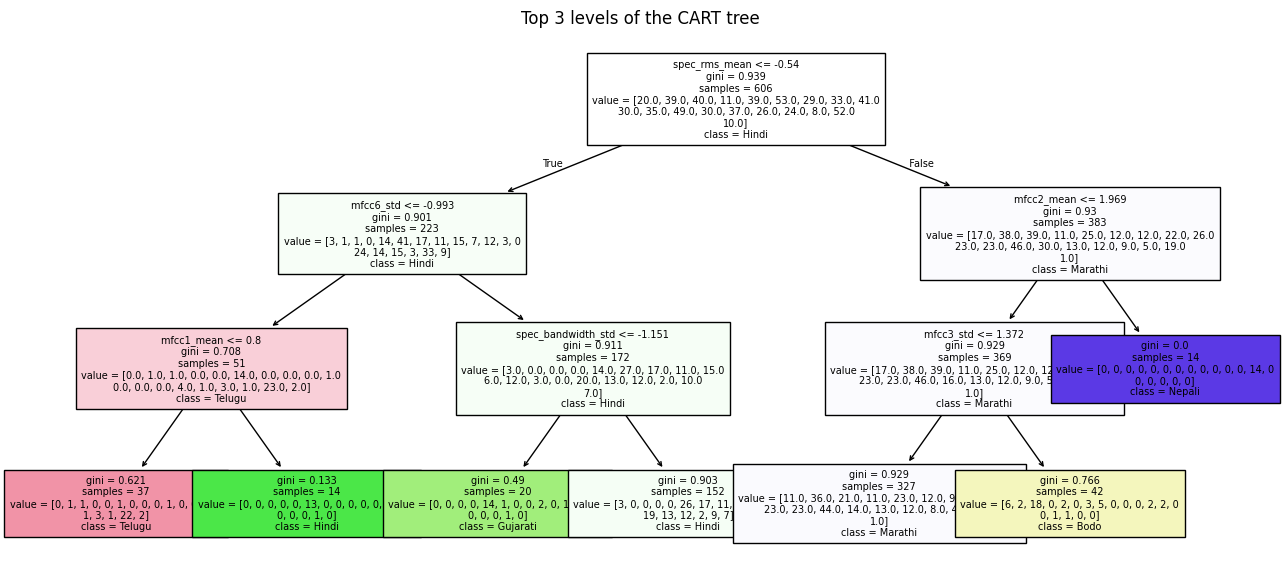

In [ ]:

from sklearn.tree import DecisionTreeClassifier, plot_tree
path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(Xtr, y_tr)
alphas = np.unique(np.quantile(path.ccp_alphas, np.linspace(0, 0.9, 8)))
gkf = GroupKFold(n_splits=3); cv_scores = []
for a in alphas:
    s = []
    for a_i, b_i in gkf.split(Xtr, y_tr, g_tr):
        t = DecisionTreeClassifier(ccp_alpha=a, random_state=SEED).fit(Xtr[a_i], y_tr[a_i]); s.append(t.score(Xtr[b_i], y_tr[b_i]))
    cv_scores.append(np.mean(s))
best_a = alphas[int(np.argmax(cv_scores))]
print("best ccp_alpha:", round(best_a, 5))
evaluate('CART (unpruned)', DecisionTreeClassifier(random_state=SEED));
cart = evaluate('CART (pruned)', DecisionTreeClassifier(ccp_alpha=best_a, random_state=SEED))
print("Pruned tree: depth =", cart.get_depth(), "| leaves =", cart.get_n_leaves())
plt.figure(figsize=(16, 7))
plot_tree(DecisionTreeClassifier(ccp_alpha=best_a, random_state=SEED, max_depth=3).fit(Xtr, y_tr),
          feature_names=feat_cols, class_names=classes, filled=True, fontsize=7)
plt.title("Top 3 levels of the CART tree"); plt.show()


## Part B: Random forest
Many trees trained on bootstrap samples with random feature selection, combined by voting. It reduces the variance of a single tree.

Random forest                       acc=0.093  macroF1=0.079


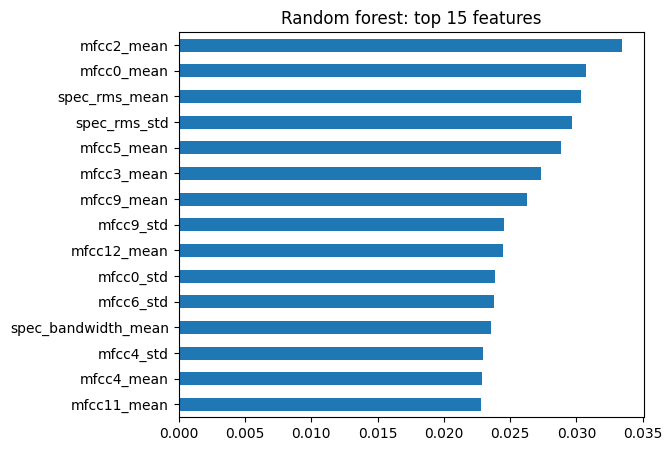

In [ ]:

from sklearn.ensemble import RandomForestClassifier
rf = evaluate('Random forest', RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))
imp = pd.Series(rf.feature_importances_, index=feat_cols).sort_values(ascending=False)[:15]
imp[::-1].plot.barh(title='Random forest: top 15 features', figsize=(6, 5)); plt.show()


## Part C: AdaBoost
Weak trees (stumps) are trained one after another; each one focuses on the examples the earlier ones got wrong. It reduces bias.

In [ ]:

from sklearn.ensemble import AdaBoostClassifier
ada = evaluate('AdaBoost', AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED))


AdaBoost                            acc=0.036  macroF1=0.024


## Comparison

,model,accuracy,macro_F1
0,CART (unpruned),0.098,0.076
1,Random forest,0.093,0.079
2,CART (pruned),0.082,0.056
3,AdaBoost,0.036,0.024


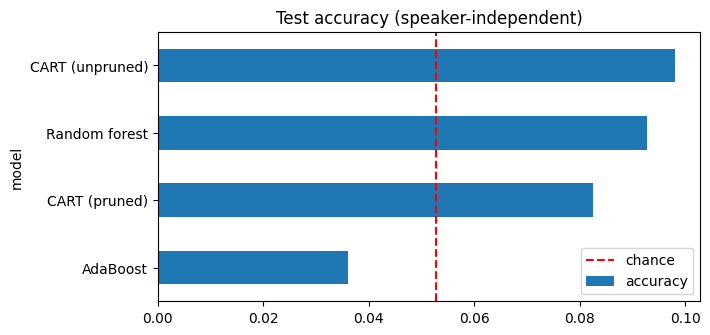

Best model: Random forest
              precision    recall  f1-score   support

    Assamese       0.67      0.31      0.42        13
     Bengali       0.00      0.00      0.00        13
        Bodo       0.00      0.00      0.00         8
       Dogri       0.00      0.00      0.00        18
    Gujarati       0.00      0.00      0.00         0
       Hindi       0.04      0.03      0.04        33
     Kannada       0.07      0.09      0.08        11
    Kashmiri       0.00      0.00      0.00         4
     Konkani       0.42      0.23      0.29        22
    Maithili       0.00      0.00      0.00        11
   Malayalam       0.22      0.20      0.21        10
     Marathi       0.00      0.00      0.00         0
      Nepali       0.50      0.20      0.29        15
        Odia       0.00      0.00      0.00         9
     Punjabi       0.00      0.00      0.00         4
      Sindhi       0.00      0.00      0.00         0
       Tamil       0.00      0.00      0.00        11
 

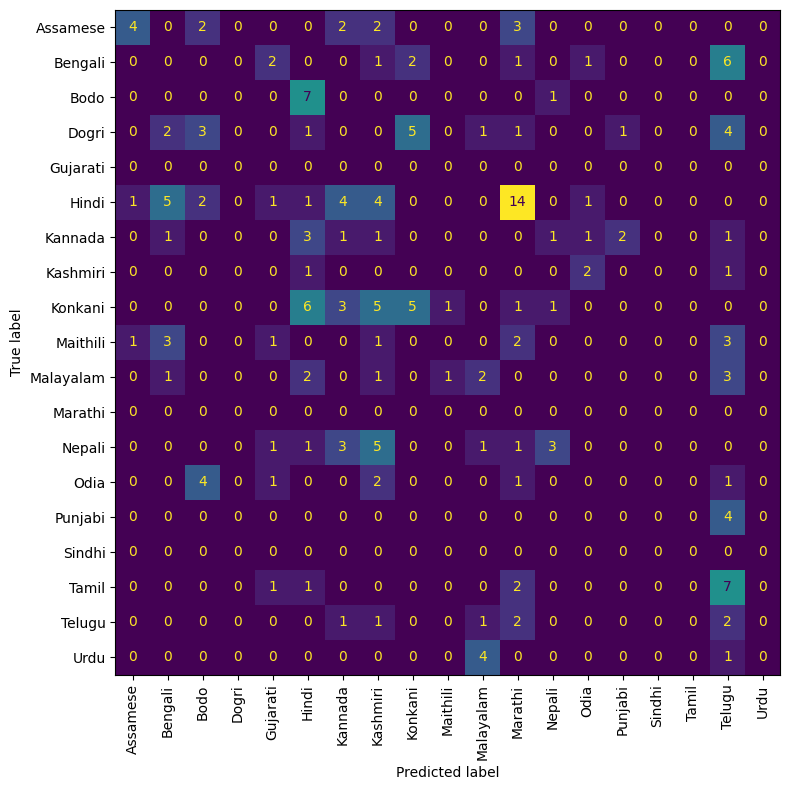

In [ ]:

res = pd.DataFrame(results, columns=['model', 'accuracy', 'macro_F1']).sort_values('accuracy', ascending=False).reset_index(drop=True)
display(res.round(3))
res.set_index('model')['accuracy'][::-1].plot.barh(figsize=(7, 3.5), title='Test accuracy (speaker-independent)')
plt.axvline(1/len(classes), color='r', ls='--', label='chance'); plt.legend(); plt.show()
res.to_csv('lahaja_unit5_comparison.csv', index=False)
best = {'CART (unpruned)': None, 'CART (pruned)': cart, 'Random forest': rf, 'AdaBoost': ada}
best_name = res.loc[res['model'] != 'CART (unpruned)', 'model'].iloc[0]
mdl = best[best_name]; pb = mdl.predict(Xte); print("Best model:", best_name)
print(classification_report(y_te, pb, labels=range(len(classes)), target_names=classes, zero_division=0))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_te, pb, labels=range(len(classes))), display_labels=classes).plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.tight_layout(); plt.show()
